# 1. Configuración del Entorno y Carga de Datos
Importación de librerías principales y lectura del dataset limpio (`Global_Superstore_Limpio.xlsx`).

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuración visual general y filtro de advertencias menores
sns.set_style("whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

# Ruta del archivo en Google Colab (asegúrate de subirlo al panel izquierdo o conectar Drive)
ruta_archivo = "Global_Superstore_Limpio.xlsx"
df = pd.read_excel(ruta_archivo)

# Verificación rápida de dimensiones y tipos de datos
print(f"Dimensiones del dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas\n")
print(df.dtypes)
display(df.head())

Dimensiones del dataset: 51,290 filas x 32 columnas

Row ID                     int64
Order ID                  object
Order Date        datetime64[ns]
Ship Date         datetime64[ns]
Ship Mode                 object
Customer ID               object
Customer Name             object
Segment                   object
City                      object
State                     object
Country                   object
Region                    object
Market                    object
Product ID                object
Product Name              object
Sub-Category              object
Category                  object
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
Shipping Cost            float64
Order Priority            object
Month                      int64
Year                       int64
Year-Month                object
Margen                   float64
Returned                  object
Person                 

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Order Priority,Month,Year,Year-Month,Margen,Returned,Person,LPI_Observado,LPI,LPI_Metodo
0,24599,in-2017-ca120551-42816,2017-03-22,2017-03-29,standard class,ca-120551,cathy armstrong,home office,herat,hirat,...,medium,3,2017,2017-03,0.139952,yes,chandrakant chaudhri,NaN,2.044923,interpolado (lineal)
1,29465,id-2015-bd116051-42248,2015-09-01,2015-09-04,second class,bd-116051,brian dahlen,consumer,herat,hirat,...,medium,9,2015,2015-09,0.429047,no,chandrakant chaudhri,NaN,2.105427,interpolado (lineal)
2,24598,in-2017-ca120551-42816,2017-03-22,2017-03-29,standard class,ca-120551,cathy armstrong,home office,herat,hirat,...,medium,3,2017,2017-03,0.039761,yes,chandrakant chaudhri,NaN,2.044923,interpolado (lineal)
3,24597,in-2017-ca120551-42816,2017-03-22,2017-03-29,standard class,ca-120551,cathy armstrong,home office,herat,hirat,...,medium,3,2017,2017-03,0.469590,yes,chandrakant chaudhri,NaN,2.044923,interpolado (lineal)
4,29464,id-2015-bd116051-42248,2015-09-01,2015-09-04,second class,bd-116051,brian dahlen,consumer,herat,hirat,...,medium,9,2015,2015-09,0.119482,no,chandrakant chaudhri,NaN,2.105427,interpolado (lineal)


# 2. Preparación de Variables Adicionales
Construimos la métrica **`Shipping Days`** (Días de envío) restando `Ship Date - Order Date` para evaluar la velocidad de despacho logístico.

In [15]:
# Construcción de días de envío
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

print("Resumen estadístico de Shipping Days:")
display(df["Shipping Days"].describe().to_frame().T)

Resumen estadístico de Shipping Days:


,count,mean,std,min,25%,50%,75%,max
Shipping Days,51290.0,3.970404,1.730238,0.0,3.0,4.0,5.0,8.0


# 3. Análisis Univariado: Variables Numéricas
Definición de funciones auxiliares para explorar la distribución central, dispersión, asimetría y presencia de valores atípicos (*outliers*).

In [16]:
def histograma(df, col, bins=50, log_scale=False, color="steelblue"):
    """
    Histograma con curva de densidad (KDE) + líneas de media y mediana.
    """
    datos = df[col].dropna()
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.histplot(datos, bins=bins, kde=True, color=color, ax=ax)

    media = datos.mean()
    mediana = datos.median()
    ax.axvline(media, color="darkorange", linestyle="--", linewidth=1.5,
               label=f"Media = {media:,.1f}")
    ax.axvline(mediana, color="black", linestyle="-", linewidth=1.5,
               label=f"Mediana = {mediana:,.1f}")

    titulo = f"Distribución de {col} (escala log)" if log_scale else f"Distribución de {col}"
    if log_scale:
        ax.set_xscale("log")

    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=9)
    sns.despine()
    plt.tight_layout()
    plt.show()

    asimetria = "positiva" if media > mediana else "negativa"
    print(f"📊 {col}: Media = {media:,.2f} | Mediana = {mediana:,.2f} | Asimetría = {asimetria}\n")


def histograma_zoom(df, col, p_inf=0.01, p_sup=0.99, bins=80, color="seagreen"):
    """
    Histograma recortado a un rango percentil para observar el comportamiento central
    sin la distorsión visual de outliers extremos.
    """
    datos = df[col].dropna()
    li = datos.quantile(p_inf)
    ls = datos.quantile(p_sup)
    datos_zoom = datos[(datos >= li) & (datos <= ls)]

    fig, ax = plt.subplots(figsize=(10, 4))
    sns.histplot(datos_zoom, bins=bins, kde=True, color=color, ax=ax)

    media = datos_zoom.mean()
    mediana = datos_zoom.median()
    ax.axvline(media, color="darkorange", linestyle="--", linewidth=1.5,
               label=f"Media = {media:,.1f}")
    ax.axvline(mediana, color="black", linestyle="-", linewidth=1.5,
               label=f"Mediana = {mediana:,.1f}")
    ax.axvline(0, color="red", linestyle=":", linewidth=1.2,
               label="Break-even (0)")

    ax.set_title(f"Distribución de {col} — Zoom al {int((p_sup-p_inf)*100)}% central",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{col} (rango: {li:,.1f} a {ls:,.1f})")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=9)
    sns.despine()
    plt.tight_layout()
    plt.show()

    print(f"🔎 Rango mostrado: {li:,.2f} a {ls:,.2f} | "
          f"Registros: {len(datos_zoom):,} de {len(datos):,} ({100*len(datos_zoom)/len(datos):.1f}%)\n")


def boxplot_detallado(df, col, log_scale=False, color="steelblue"):
    """
    Boxplot horizontal con resumen estadístico e identificación de outliers.
    """
    datos = df[col].dropna()

    q1 = datos.quantile(0.25)
    mediana = datos.median()
    q3 = datos.quantile(0.75)
    media = datos.mean()
    iqr = q3 - q1
    li = q1 - 1.5 * iqr
    ls = q3 + 1.5 * iqr
    outliers = datos[(datos < li) | (datos > ls)]
    pct_out = 100 * len(outliers) / len(datos)

    fig, ax = plt.subplots(figsize=(11, 3))
    sns.boxplot(
        x=datos, ax=ax, color=color, width=0.4, fliersize=3,
        flierprops=dict(marker="o", markerfacecolor="crimson",
                        markeredgecolor="crimson", alpha=0.25, markersize=3),
        medianprops=dict(color="black", linewidth=2),
    )
    ax.axvline(media, color="darkorange", linestyle="--", linewidth=1.5,
               label=f"Media = {media:,.2f}")
    ax.axvline(mediana, color="black", linestyle="-", linewidth=1.5,
               label=f"Mediana = {mediana:,.2f}")

    titulo = f"Boxplot de {col} (escala log)" if log_scale else f"Boxplot de {col}"
    if log_scale:
        ax.set_xscale("log")

    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_yticks([])
    ax.legend(loc="upper right", fontsize=9)
    sns.despine(left=True)

    stats = (f"Mín: {datos.min():,.2f}  |  Q1: {q1:,.2f}  |  "
             f"Mediana: {mediana:,.2f}  |  Q3: {q3:,.2f}  |  Máx: {datos.max():,.2f}\n"
             f"IQR: {iqr:,.2f}  |  Outliers: {len(outliers):,} ({pct_out:.1f}%)")
    ax.text(0.5, -0.55, stats, transform=ax.transAxes, ha="center", va="top",
            fontsize=9, bbox=dict(boxstyle="round,pad=0.5",
                                  facecolor="#f5f5f5", edgecolor="#cccccc"))
    plt.tight_layout()
    plt.show()

## 3.1 Distribución con Histogramas
* **Sales:** Escala logarítmica debido a la amplitud de órdenes de magnitud (muchos pedidos pequeños y pocas ventas corporativas muy altas).
* **Profit:** Escala lineal para incluir pérdidas (valores negativos), complementado con un zoom al 98% central.
* **Shipping Days:** Variable discreta para evaluar consistencia logística.

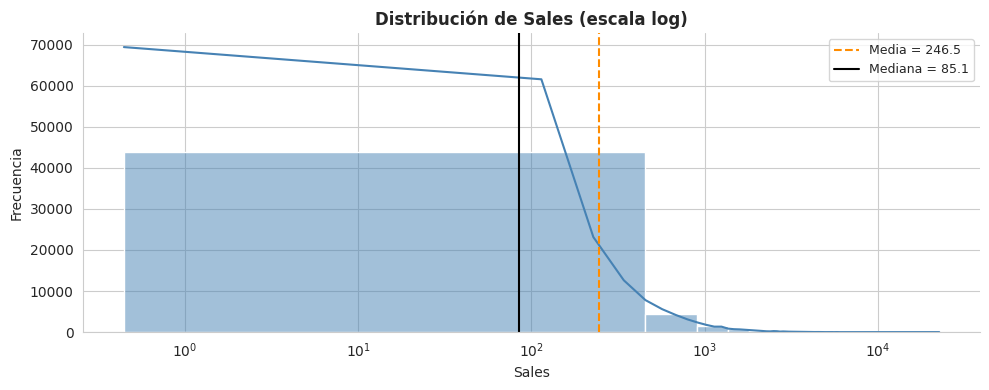

📊 Sales: Media = 246.49 | Mediana = 85.05 | Asimetría = positiva



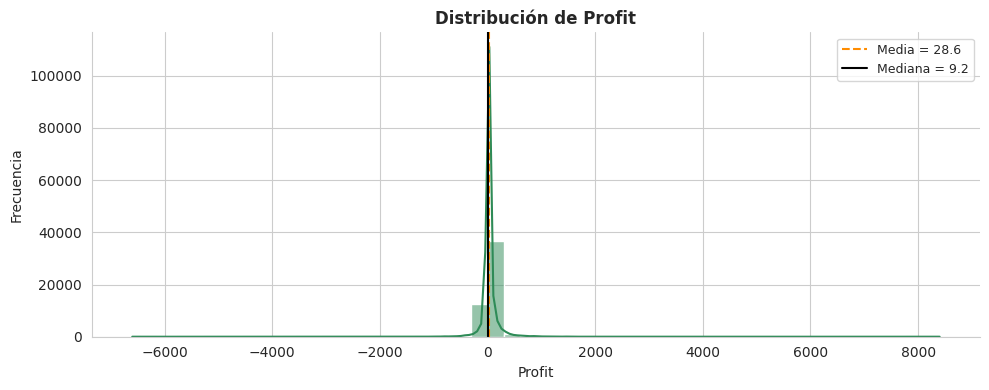

📊 Profit: Media = 28.61 | Mediana = 9.24 | Asimetría = positiva



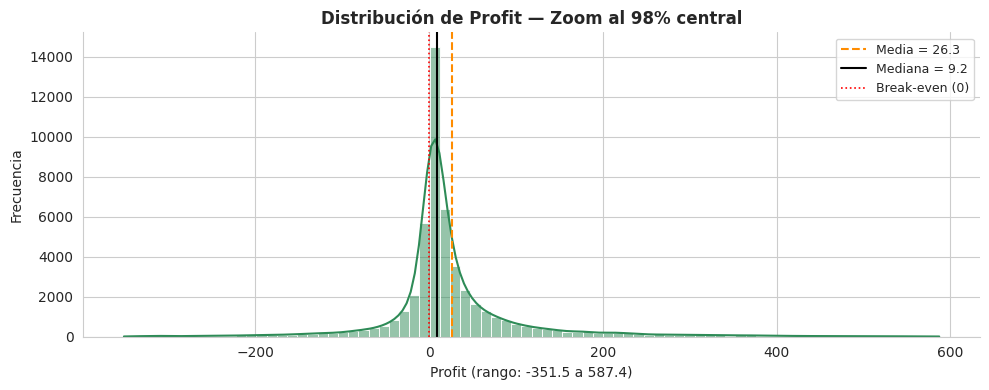

🔎 Rango mostrado: -351.51 a 587.36 | Registros: 50,264 de 51,290 (98.0%)



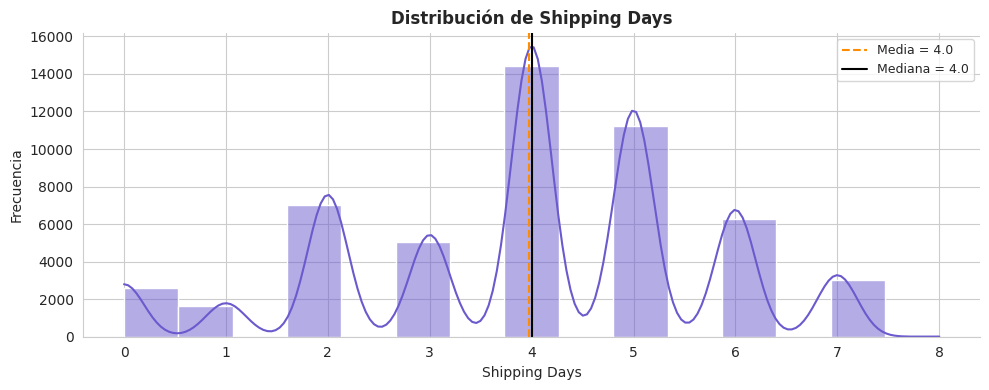

📊 Shipping Days: Media = 3.97 | Mediana = 4.00 | Asimetría = negativa



In [17]:
# 1. Sales (Ventas)
histograma(df, "Sales", log_scale=True, color="steelblue")

# 2. Profit (Ganancia) - General y Zoom al 98% central
histograma(df, "Profit", log_scale=False, color="seagreen")
histograma_zoom(df, "Profit", p_inf=0.01, p_sup=0.99, color="seagreen")

# 3. Shipping Days (Días de envío)
histograma(df, "Shipping Days", bins=15, color="slateblue")

## 3.2 Análisis de Dispersión y Outliers (Boxplots)
Evaluación del rango intercuartílico (IQR) y proporción de valores extremos. Los outliers en `Sales` y `Profit` corresponden a transacciones reales del negocio (ventas corporativas o descuentos agresivos), por lo que se mantienen.

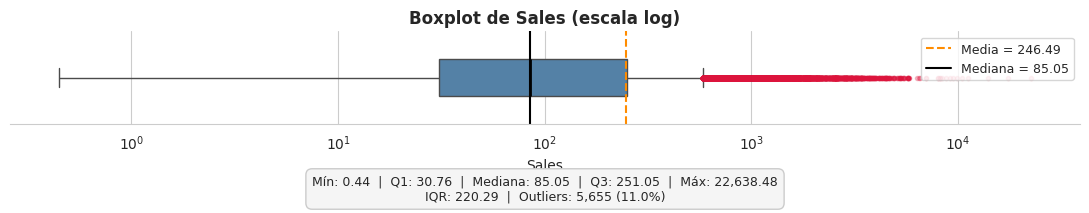

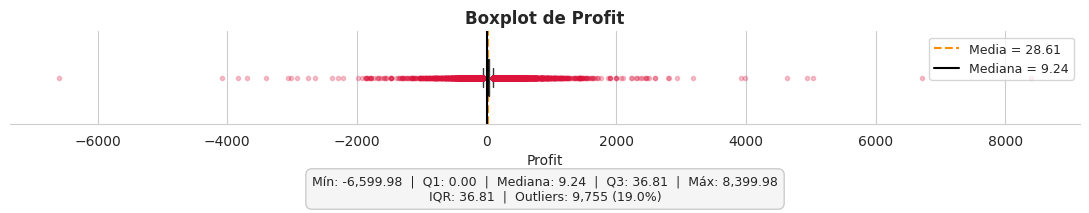

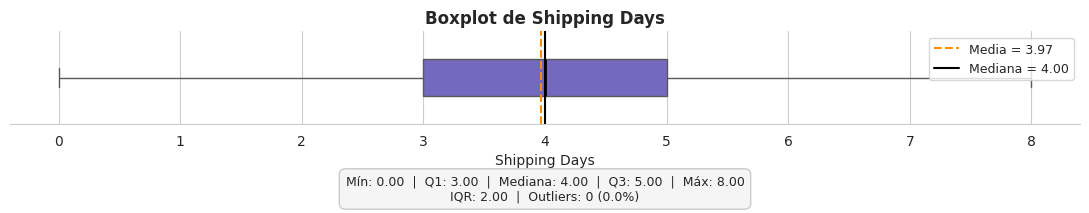

In [18]:
boxplot_detallado(df, "Sales", log_scale=True, color="steelblue")
boxplot_detallado(df, "Profit", log_scale=False, color="seagreen")
boxplot_detallado(df, "Shipping Days", log_scale=False, color="slateblue")

# 4. Análisis Univariado: Variables Categóricas
Comparación del volumen de transacciones (`count`) frente al ingreso generado (`Sales`) por **Segmento**, **Mercado** y **Categoría**.

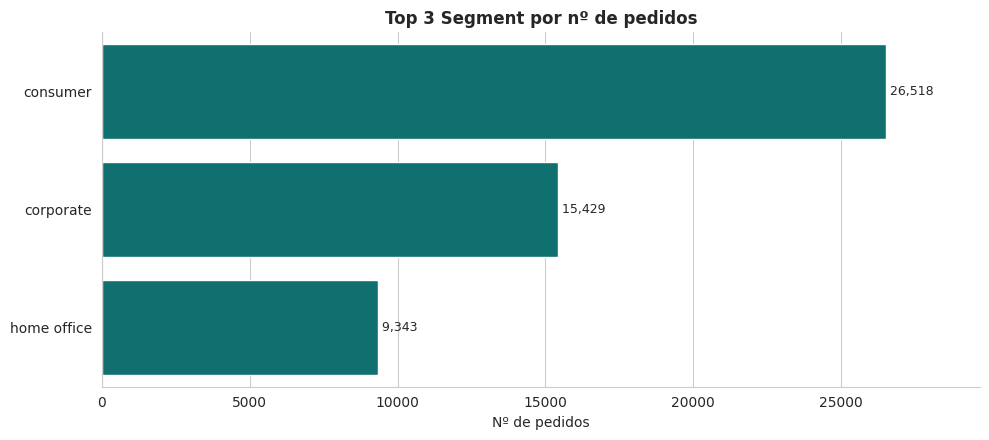

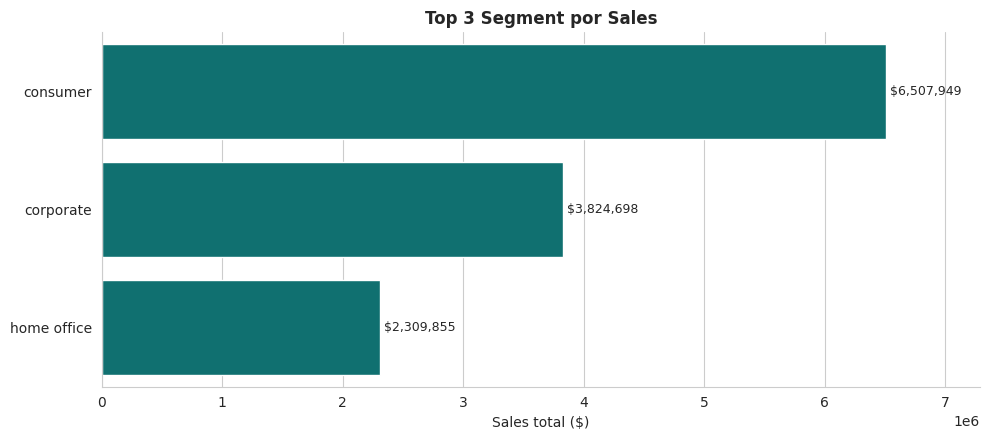

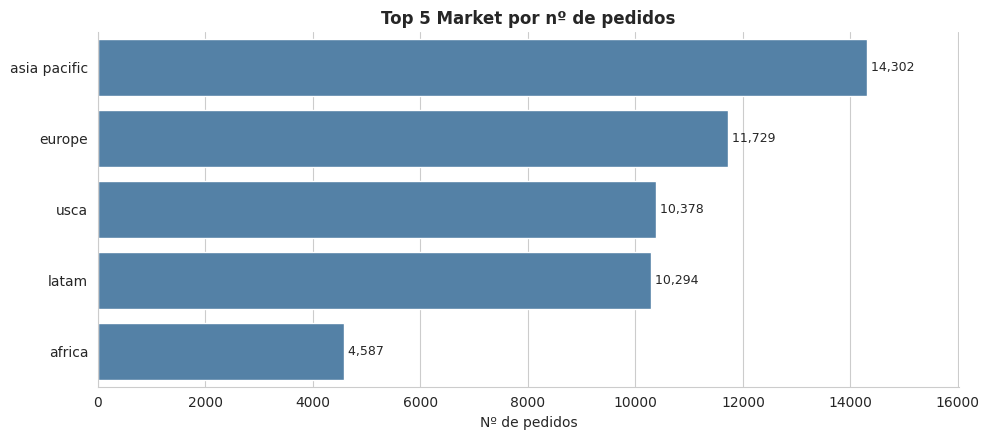

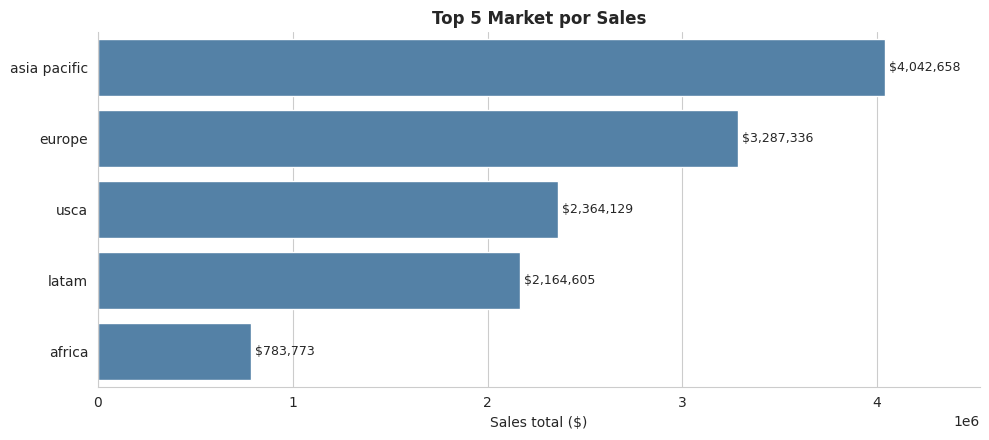

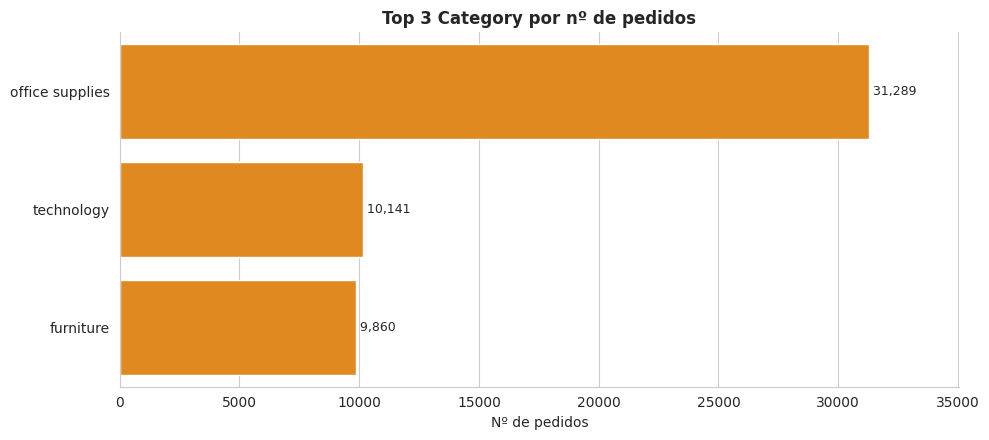

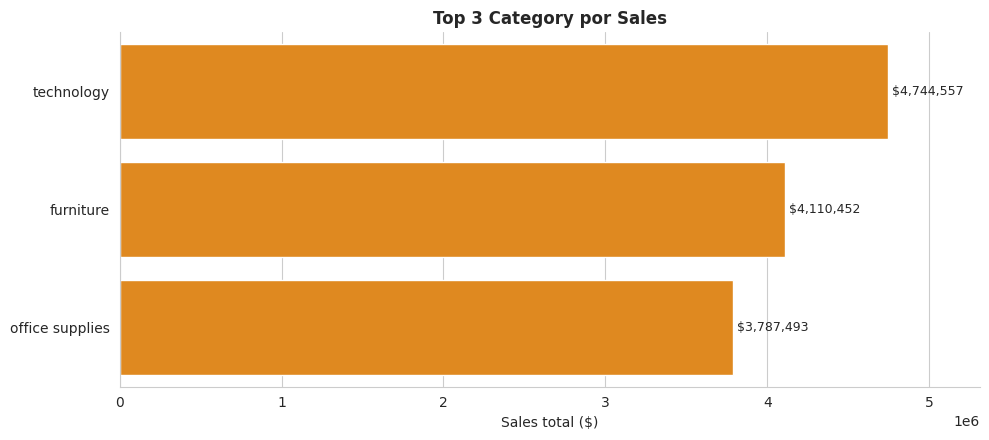

In [19]:
def frecuencia_categorica(df, col, metrica="Sales", top_n=10, color="steelblue"):
    """
    Gráfico de barras horizontales con el top N de categorías según volumen de pedidos o métrica monetaria.
    """
    if metrica == "count":
        resumen = df[col].value_counts().head(top_n)
        xlabel = "Nº de pedidos"
        titulo = f"Top {top_n} {col} por nº de pedidos"
    else:
        resumen = (df.groupby(col)[metrica].sum()
                     .sort_values(ascending=False)
                     .head(top_n))
        xlabel = f"{metrica} total ($)"
        titulo = f"Top {top_n} {col} por {metrica}"

    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.barplot(x=resumen.values, y=resumen.index, color=color, ax=ax)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")

    # Ajuste de margen derecho para que el texto no se corte
    ax.set_xlim(0, resumen.values.max() * 1.12)

    for i, v in enumerate(resumen.values):
        formato = f" {v:,}" if metrica == "count" else f" ${v:,.0f}"
        ax.text(v, i, formato, va="center", fontsize=9)

    sns.despine()
    plt.tight_layout()
    plt.show()


# ---------- 1. SEGMENTO ----------
frecuencia_categorica(df, "Segment", metrica="count", top_n=3, color="teal")
frecuencia_categorica(df, "Segment", metrica="Sales", top_n=3, color="teal")

# ---------- 2. MERCADO ----------
frecuencia_categorica(df, "Market", metrica="count", top_n=5, color="steelblue")
frecuencia_categorica(df, "Market", metrica="Sales", top_n=5, color="steelblue")

# ---------- 3. CATEGORÍA ----------
frecuencia_categorica(df, "Category", metrica="count", top_n=3, color="darkorange")
frecuencia_categorica(df, "Category", metrica="Sales", top_n=3, color="darkorange")

# 5. Análisis Bivariado: Descuentos vs. Rentabilidad (`Discount` vs `Profit`)
En el análisis univariado observamos una cola importante de transacciones con pérdidas (`Profit < 0`). Aquí evaluamos cómo la política de descuentos (`Discount`) erosiona el margen y destruye valor a partir de cierto umbral.

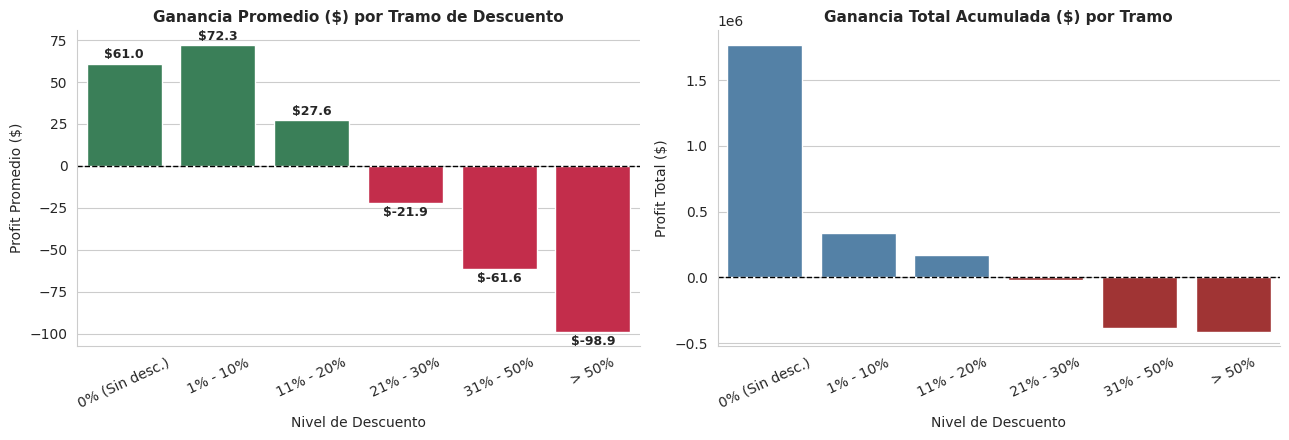

,Pedidos,Profit_Total,Profit_Promedio,Margen_Promedio
Tramo_Descuento,,,,
0% (Sin desc.),"29,009","$1,770,695.27",$61.04,26.5%
1% - 10%,"4,679","$338,189.26",$72.28,17.1%
11% - 20%,"6,274","$173,254.84",$27.61,13.7%
21% - 30%,967,"$-21,155.61",$-21.88,-3.9%
31% - 50%,"6,189","$-380,944.82",$-61.55,-33.8%
> 50%,"4,172","$-412,581.66",$-98.89,-114.7%


In [20]:
def analizar_descuentos_profit(df):
    """
    Evalúa la relación entre el nivel de descuento aplicado y la ganancia obtenida,
    combinando un gráfico de dispersión/tendencia y agrupación por tramos de descuento.
    """
    # Crear tramos de descuento para facilitar la lectura de negocio
    bins = [-0.01, 0.0, 0.10, 0.20, 0.30, 0.50, 1.0]
    labels = ["0% (Sin desc.)", "1% - 10%", "11% - 20%", "21% - 30%", "31% - 50%", "> 50%"]
    df_temp = df.copy()
    df_temp["Tramo_Descuento"] = pd.cut(df_temp["Discount"], bins=bins, labels=labels)

    resumen_desc = df_temp.groupby("Tramo_Descuento", observed=False).agg(
        Pedidos=("Order ID", "count"),
        Profit_Total=("Profit", "sum"),
        Profit_Promedio=("Profit", "mean"),
        Margen_Promedio=("Margen", "mean")
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Gráfico 1: Profit promedio por tramo de descuento
    colores = ["seagreen" if v >= 0 else "crimson" for v in resumen_desc["Profit_Promedio"]]
    sns.barplot(x=resumen_desc.index, y=resumen_desc["Profit_Promedio"], palette=colores, ax=axes[0])
    axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[0].set_title("Ganancia Promedio ($) por Tramo de Descuento", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Nivel de Descuento")
    axes[0].set_ylabel("Profit Promedio ($)")
    axes[0].tick_params(axis="x", rotation=25)

    for i, v in enumerate(resumen_desc["Profit_Promedio"]):
        axes[0].text(i, v + (3 if v >= 0 else -8), f"${v:,.1f}", ha="center", fontsize=9, fontweight="bold")

    # Gráfico 2: Profit Total acumulado por tramo
    colores_tot = ["steelblue" if v >= 0 else "firebrick" for v in resumen_desc["Profit_Total"]]
    sns.barplot(x=resumen_desc.index, y=resumen_desc["Profit_Total"], palette=colores_tot, ax=axes[1])
    axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[1].set_title("Ganancia Total Acumulada ($) por Tramo", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Nivel de Descuento")
    axes[1].set_ylabel("Profit Total ($)")
    axes[1].tick_params(axis="x", rotation=25)

    sns.despine()
    plt.tight_layout()
    plt.show()

    display(resumen_desc.style.format({
        "Pedidos": "{:,}",
        "Profit_Total": "${:,.2f}",
        "Profit_Promedio": "${:,.2f}",
        "Margen_Promedio": "{:.1%}"
    }))

analizar_descuentos_profit(df)

## 5.1 Auditoría del "Subsidio Oculto": Descuentos vs. Costo de Envío en Pedidos con Pérdida
Filtramos exclusivamente las transacciones deficitarias (`Profit < 0`) para diagnosticar si la empresa está aplicando políticas de precios suicidas: bonificando el precio del producto con descuentos agresivos y, además, asumiendo altos costos de envío (`Shipping Cost`) de su propio bolsillo.

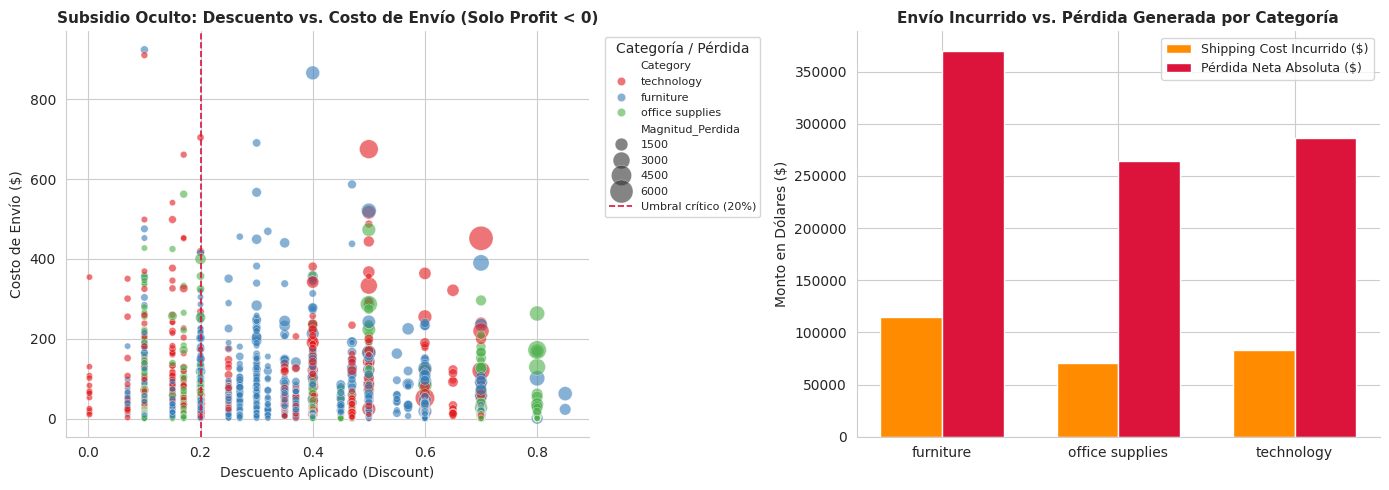

Total de transacciones con pérdida: 12,544 (24.5% del total)
Pérdida acumulada en estos pedidos: $-920,646.16
Costo de envío gastado en pedidos que dieron pérdida: $268,374.06



In [21]:
def auditar_subsidio_oculto(df):
    """
    Gráfico de dispersión (scatterplot) sobre pedidos con pérdidas (Profit < 0)
    contrastando el descuento otorgado frente al gasto logístico incurrido.
    """
    perdidas = df[df["Profit"] < 0].copy()
    perdidas["Magnitud_Perdida"] = perdidas["Profit"].abs()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Scatterplot: Discount vs Shipping Cost en pedidos deficitarios
    sns.scatterplot(
        data=perdidas, x="Discount", y="Shipping Cost",
        hue="Category", size="Magnitud_Perdida", sizes=(20, 300),
        alpha=0.6, palette="Set1", ax=axes[0]
    )
    axes[0].axvline(0.20, color="crimson", linestyle="--", linewidth=1.2, label="Umbral crítico (20%)")
    axes[0].set_title("Subsidio Oculto: Descuento vs. Costo de Envío (Solo Profit < 0)",
                      fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Descuento Aplicado (Discount)")
    axes[0].set_ylabel("Costo de Envío ($)")
    axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Categoría / Pérdida")

    # 2. Comparativa de gasto en envío y pérdida neta por Categoría (en pedidos con pérdida)
    resumen_sub = perdidas.groupby("Category").agg(
        Pedidos_Perdida=("Order ID", "count"),
        Envio_Pagado=("Shipping Cost", "sum"),
        Perdida_Neta=("Profit", "sum")
    ).reset_index()

    x = np.arange(len(resumen_sub["Category"]))
    width = 0.35
    axes[1].bar(x - width/2, resumen_sub["Envio_Pagado"], width, label="Shipping Cost Incurrido ($)", color="darkorange")
    axes[1].bar(x + width/2, resumen_sub["Perdida_Neta"].abs(), width, label="Pérdida Neta Absoluta ($)", color="crimson")

    axes[1].set_xticks(x)
    axes[1].set_xticklabels(resumen_sub["Category"])
    axes[1].set_title("Envío Incurrido vs. Pérdida Generada por Categoría", fontsize=11, fontweight="bold")
    axes[1].set_ylabel("Monto en Dólares ($)")
    axes[1].legend(fontsize=9)

    sns.despine()
    plt.tight_layout()
    plt.show()

    print(f"Total de transacciones con pérdida: {len(perdidas):,} ({100*len(perdidas)/len(df):.1f}% del total)")
    print(f"Pérdida acumulada en estos pedidos: ${perdidas['Profit'].sum():,.2f}")
    print(f"Costo de envío gastado en pedidos que dieron pérdida: ${perdidas['Shipping Cost'].sum():,.2f}\n")

auditar_subsidio_oculto(df)

# 6. Desempeño por Subcategoría (`Sales` vs `Profit`)
Aunque las 3 categorías principales son rentables a nivel global, al desglosar por **`Sub-Category`** identificamos productos específicos con márgenes negativos crónicos (como *Tables*).

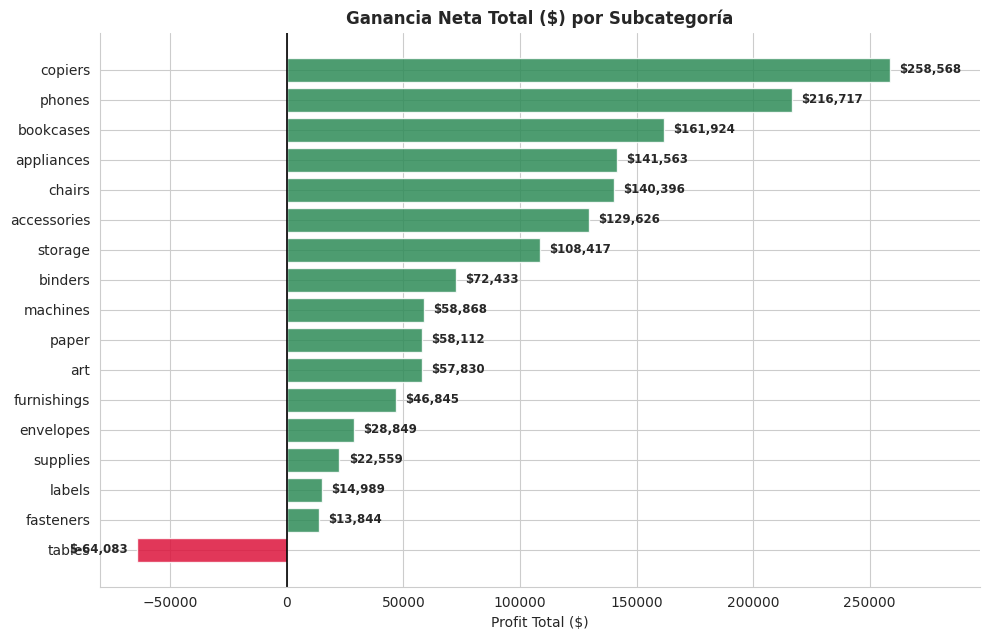

In [22]:
def rentabilidad_subcategorias(df):
    """
    Compara el Profit Total por Sub-Category, diferenciando visualmente
    las líneas de producto que suman ganancias de las que generan pérdidas netas.
    """
    sub_resumen = (df.groupby(["Category", "Sub-Category"])
                     .agg(Sales=("Sales", "sum"),
                          Profit=("Profit", "sum"),
                          Margen_Medio=("Margen", "mean"))
                     .reset_index()
                     .sort_values(by="Profit", ascending=True))

    fig, ax = plt.subplots(figsize=(10, 6.5))
    colores = ["crimson" if p < 0 else "seagreen" for p in sub_resumen["Profit"]]

    bars = ax.barh(sub_resumen["Sub-Category"], sub_resumen["Profit"], color=colores, alpha=0.85)
    ax.axvline(0, color="black", linewidth=1.2, linestyle="-")

    ax.set_title("Ganancia Neta Total ($) por Subcategoría", fontsize=12, fontweight="bold")
    ax.set_xlabel("Profit Total ($)")
    ax.set_xlim(sub_resumen["Profit"].min() * 1.25, sub_resumen["Profit"].max() * 1.15)

    for bar in bars:
        val = bar.get_width()
        offset = 4000 if val >= 0 else -4000
        ha = "left" if val >= 0 else "right"
        ax.text(val + offset, bar.get_y() + bar.get_height()/2,
                f"${val:,.0f}", va="center", ha=ha, fontsize=8.5, fontweight="bold")

    sns.despine()
    plt.tight_layout()
    plt.show()

rentabilidad_subcategorias(df)

# 8. Operación Logística, Devoluciones e Índice de Desempeño Logístico (`LPI`)
Analizamos cómo se relacionan la prioridad del pedido (`Order Priority`), el modo de envío (`Ship Mode`), los días reales de despacho (`Shipping Days`), la tasa de devoluciones (`Returned`) y el índice logístico del país (`LPI`).

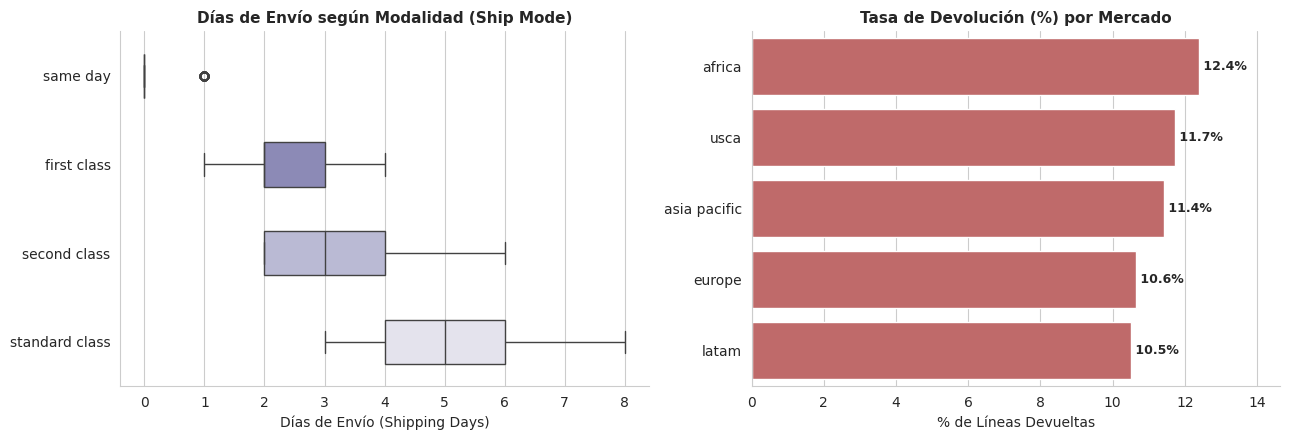

Resumen Logístico e Índice LPI por Mercado:


,Pedidos,Dias_Envio_Medio,Costo_Envio_Medio,LPI_Promedio,Tasa_Devolucion
Market,,,,,
usca,"10,378",3.95 días,$23.84,3.95,11.74%
europe,"11,729",3.99 días,$29.75,3.82,10.64%
asia pacific,"14,302",3.97 días,$30.62,3.32,11.43%
latam,"10,294",4.00 días,$22.83,2.83,10.51%
africa,"4,587",3.91 días,$19.37,2.71,12.40%


In [23]:
def analisis_logistico(df):
    """
    Cruza los días de envío por Modo de Envío y analiza la tasa de devolución por Mercado.
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # 1. Boxplot de Shipping Days por Ship Mode
    orden_modos = (df.groupby("Ship Mode")["Shipping Days"]
                     .median()
                     .sort_values()
                     .index)
    sns.boxplot(data=df, x="Shipping Days", y="Ship Mode", order=orden_modos,
                palette="Purples_r", width=0.5, ax=axes[0])
    axes[0].set_title("Días de Envío según Modalidad (Ship Mode)", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Días de Envío (Shipping Days)")
    axes[0].set_ylabel("")

    # 2. Tasa de devolución (%) por Mercado
    df_ret = df.copy()
    df_ret["Es_Devuelto"] = df_ret["Returned"].astype(str).str.lower().isin(["yes", "si", "sí", "1", "true"])
    tasa_mercado = (df_ret.groupby("Market")["Es_Devuelto"].mean() * 100).sort_values(ascending=False)

    sns.barplot(x=tasa_mercado.values, y=tasa_mercado.index, color="indianred", ax=axes[1])
    axes[1].set_title("Tasa de Devolución (%) por Mercado", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("% de Líneas Devueltas")
    axes[1].set_ylabel("")
    axes[1].set_xlim(0, tasa_mercado.max() * 1.18)

    for i, v in enumerate(tasa_mercado.values):
        axes[1].text(v, i, f" {v:.1f}%", va="center", fontsize=9, fontweight="bold")

    sns.despine()
    plt.tight_layout()
    plt.show()

    # Resumen de LPI y Costos de Envío por Mercado (usando df_ret que contiene 'Es_Devuelto')
    if "LPI" in df_ret.columns:
        resumen_lpi = df_ret.groupby("Market").agg(
            Pedidos=("Order ID", "count"),
            Dias_Envio_Medio=("Shipping Days", "mean"),
            Costo_Envio_Medio=("Shipping Cost", "mean"),
            LPI_Promedio=("LPI", "mean"),
            Tasa_Devolucion=("Es_Devuelto", lambda x: x.mean() * 100)
        ).sort_values(by="LPI_Promedio", ascending=False)

        print("Resumen Logístico e Índice LPI por Mercado:")
        display(resumen_lpi.style.format({
            "Pedidos": "{:,}",
            "Dias_Envio_Medio": "{:.2f} días",
            "Costo_Envio_Medio": "${:,.2f}",
            "LPI_Promedio": "{:.2f}",
            "Tasa_Devolucion": "{:.2f}%"
        }))

analisis_logistico(df)

# 9. Matriz de Correlación Multivariada
Mapa de calor (*Heatmap*) con las correlaciones de Pearson entre las variables cuantitativas clave del negocio.

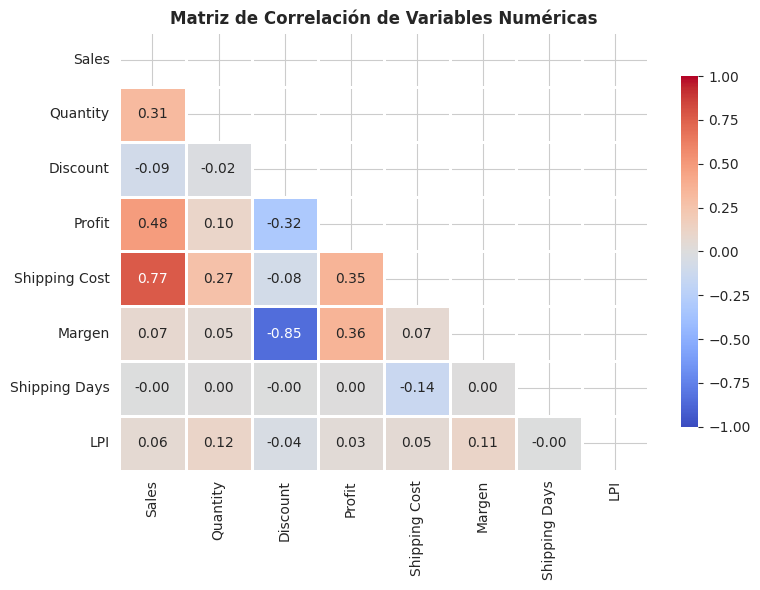

In [24]:
def matriz_correlacion(df):
    """
    Calcula y grafica la matriz de correlación entre las métricas numéricas relevantes.
    """
    cols_num = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost", "Margen", "Shipping Days"]
    if "LPI" in df.columns:
        cols_num.append("LPI")

    # Filtrar solo las columnas que existan en el df
    cols_disponibles = [c for c in cols_num if c in df.columns]
    corr = df[cols_disponibles].corr()

    fig, ax = plt.subplots(figsize=(8, 6))
    mask = np.triu(np.ones_like(corr, dtype=bool)) # Ocultar mitad superior redundante

    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, center=0, linewidths=0.8, cbar_kws={"shrink": 0.8}, ax=ax)

    ax.set_title("Matriz de Correlación de Variables Numéricas", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

matriz_correlacion(df)

# 10. Auditoría de Devoluciones: El Impacto del "Dinero Fantasma"
En muchos reportes contables preliminares se suman todas las ventas sin descontar los pedidos marcados como devueltos (`Returned == 'yes'`). Aquí contrastamos el **Escenario Bruto (con dinero fantasma)** frente al **Escenario Real Neto (sin devoluciones)** para medir cuánto ingreso y ganancia se esfuman realmente.

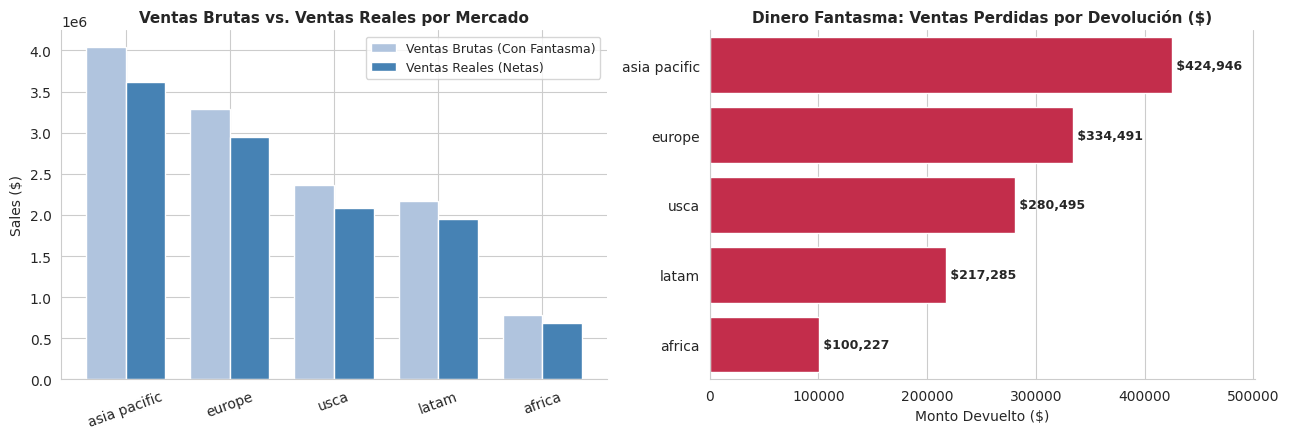

RESUMEN DE DINERO FANTASMA (DEVOLUCIONES):
   • Ventas Brutas: $12,642,501.91  -->  Ventas Reales: $11,285,058.62 (Fantasma: -$1,357,443.29)
   • Profit Bruto:  $1,467,457.29  -->  Profit Real:   $1,330,860.24 (Profit no realizado: -$136,597.05)



In [25]:
def auditar_dinero_fantasma(df):
    """
    Compara Ventas y Ganancias Brutas vs. Reales (excluyendo pedidos devueltos)
    para cuantificar el 'dinero fantasma' por Mercado y Categoría.
    """
    df_temp = df.copy()
    df_temp["Devuelto_Flag"] = df_temp["Returned"].astype(str).str.lower().isin(["yes", "si", "sí", "1", "true"])

    # Métricas globales
    ventas_brutas = df_temp["Sales"].sum()
    ventas_fantasma = df_temp.loc[df_temp["Devuelto_Flag"], "Sales"].sum()
    ventas_reales = ventas_brutas - ventas_fantasma

    profit_bruto = df_temp["Profit"].sum()
    profit_fantasma = df_temp.loc[df_temp["Devuelto_Flag"], "Profit"].sum()
    profit_real = profit_bruto - profit_fantasma

    # Agrupación por Mercado
    mercado_comp = df_temp.groupby("Market").agg(
        Ventas_Brutas=("Sales", "sum"),
        Ventas_Reales=("Sales", lambda s: s[~df_temp.loc[s.index, "Devuelto_Flag"]].sum()),
        Profit_Bruto=("Profit", "sum"),
        Profit_Real=("Profit", lambda p: p[~df_temp.loc[p.index, "Devuelto_Flag"]].sum())
    )
    mercado_comp["Dinero_Fantasma_Sales"] = mercado_comp["Ventas_Brutas"] - mercado_comp["Ventas_Reales"]
    mercado_comp = mercado_comp.sort_values(by="Ventas_Brutas", ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Gráfico 1: Ventas Brutas vs Reales por Mercado
    x = np.arange(len(mercado_comp.index))
    width = 0.38
    axes[0].bar(x - width/2, mercado_comp["Ventas_Brutas"], width, label="Ventas Brutas (Con Fantasma)", color="lightsteelblue")
    axes[0].bar(x + width/2, mercado_comp["Ventas_Reales"], width, label="Ventas Reales (Netas)", color="steelblue")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(mercado_comp.index, rotation=20)
    axes[0].set_title("Ventas Brutas vs. Ventas Reales por Mercado", fontsize=11, fontweight="bold")
    axes[0].set_ylabel("Sales ($)")
    axes[0].legend(fontsize=9)

    # Gráfico 2: Dinero Fantasma perdido en devoluciones por Mercado
    sns.barplot(x=mercado_comp["Dinero_Fantasma_Sales"], y=mercado_comp.index, color="crimson", ax=axes[1])
    axes[1].set_title("Dinero Fantasma: Ventas Perdidas por Devolución ($)", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Monto Devuelto ($)")
    axes[1].set_ylabel("")
    axes[1].set_xlim(0, mercado_comp["Dinero_Fantasma_Sales"].max() * 1.18)

    for i, v in enumerate(mercado_comp["Dinero_Fantasma_Sales"]):
        axes[1].text(v, i, f" ${v:,.0f}", va="center", fontsize=9, fontweight="bold")

    sns.despine()
    plt.tight_layout()
    plt.show()

    print(f"RESUMEN DE DINERO FANTASMA (DEVOLUCIONES):")
    print(f"   • Ventas Brutas: ${ventas_brutas:,.2f}  -->  Ventas Reales: ${ventas_reales:,.2f} (Fantasma: -${ventas_fantasma:,.2f})")
    print(f"   • Profit Bruto:  ${profit_bruto:,.2f}  -->  Profit Real:   ${profit_real:,.2f} (Profit no realizado: -${profit_fantasma:,.2f})\n")

auditar_dinero_fantasma(df)

# 11. Auditoría del Índice Logístico (`LPI`): Valores Observados vs. Interpolados y Contradicciones
Evaluamos la calidad del cruce con el *Logistics Performance Index* (`LPI`), diferenciando según `LPI_Metodo` (observado vs. interpolado/imputado) y verificando si existen contradicciones entre el puntaje logístico de un país y los tiempos o costos reales de envío que experimenta la empresa.

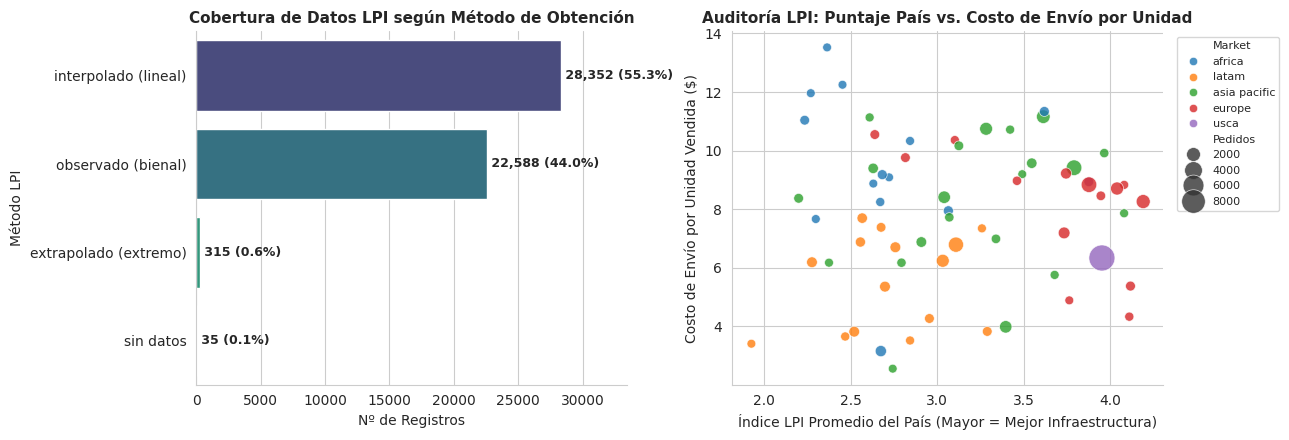

In [26]:
def auditar_lpi(df):
    """
    Analiza la cobertura de LPI_Metodo y contrasta el LPI promedio por país
    frente al costo de envío unitario y días reales de despacho.
    """
    if "LPI" not in df.columns or "LPI_Metodo" not in df.columns:
        print("Las columnas LPI / LPI_Metodo no están presentes en el dataset.")
        return

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # 1. Proporción de registros según LPI_Metodo
    conteo_metodo = df["LPI_Metodo"].value_counts()
    sns.barplot(x=conteo_metodo.values, y=conteo_metodo.index, palette="viridis", ax=axes[0])
    axes[0].set_title("Cobertura de Datos LPI según Método de Obtención", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Nº de Registros")
    axes[0].set_ylabel("Método LPI")
    axes[0].set_xlim(0, conteo_metodo.max() * 1.18)

    for i, v in enumerate(conteo_metodo.values):
        pct = 100 * v / len(df)
        axes[0].text(v, i, f" {v:,} ({pct:.1f}%)", va="center", fontsize=9, fontweight="bold")

    # 2. Contradicción LPI vs Días de Envío / Costo a nivel País (Top 30 países con más pedidos)
    paises_top = (df.groupby(["Country", "Market"])
                    .agg(Pedidos=("Order ID", "count"),
                         LPI_Medio=("LPI", "mean"),
                         Shipping_Days_Medio=("Shipping Days", "mean"),
                         Costo_Por_Unidad=("Shipping Cost", lambda s: s.sum() / df.loc[s.index, "Quantity"].sum()))
                    .reset_index())
    paises_top = paises_top[paises_top["Pedidos"] >= 100] # Filtrar países con volumen representativo

    sns.scatterplot(
        data=paises_top, x="LPI_Medio", y="Costo_Por_Unidad",
        hue="Market", size="Pedidos", sizes=(40, 350), alpha=0.8, ax=axes[1]
    )
    axes[1].set_title("Auditoría LPI: Puntaje País vs. Costo de Envío por Unidad", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Índice LPI Promedio del País (Mayor = Mejor Infraestructura)")
    axes[1].set_ylabel("Costo de Envío por Unidad Vendida ($)")
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

    sns.despine()
    plt.tight_layout()
    plt.show()

auditar_lpi(df)

# 12. Auditoría de Integridad Temporal (Cobertura de Meses y Cierre)
Verificamos la distribución de pedidos por Año (`Year`) y Mes (`Month`) mediante una matriz temporal para confirmar la estacionalidad de fin de año (Q4) y validar si todos los periodos anuales están completos al cierre del corte de datos.

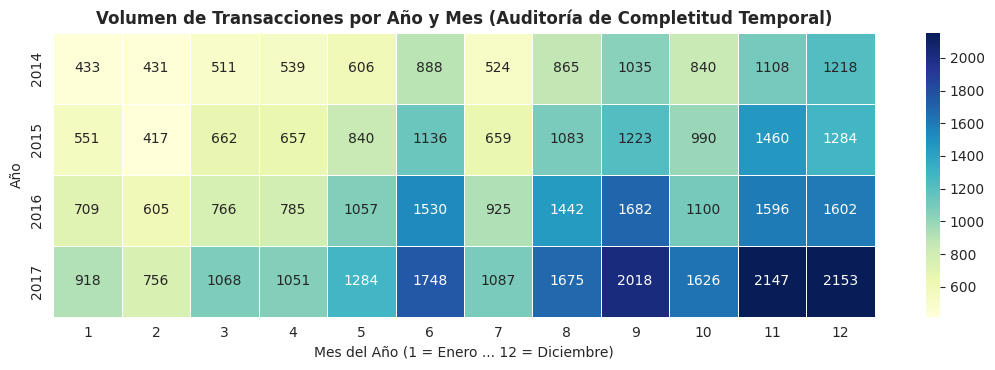

Rango exacto de Order Date: 2014-01-01 al 2017-12-31
Rango exacto de Ship Date:  2014-01-03 al 2018-01-07


In [27]:
def auditar_cierre_temporal(df):
    """
    Crea un mapa de calor Año vs. Mes con el volumen de pedidos para auditar
    la completitud de los cierres anuales y detectar picos estacionales.
    """
    tabla_tiempo = df.pivot_table(
        index="Year", columns="Month", values="Order ID",
        aggfunc="count", fill_value=0
    )

    fig, ax = plt.subplots(figsize=(11, 3.8))
    sns.heatmap(tabla_tiempo, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.5, ax=ax)

    ax.set_title("Volumen de Transacciones por Año y Mes (Auditoría de Completitud Temporal)",
                 fontsize=12, fontweight="bold")
    ax.set_xlabel("Mes del Año (1 = Enero ... 12 = Diciembre)")
    ax.set_ylabel("Año")
    plt.tight_layout()
    plt.show()

    print(f"Rango exacto de Order Date: {df['Order Date'].min().strftime('%Y-%m-%d')} al {df['Order Date'].max().strftime('%Y-%m-%d')}")
    print(f"Rango exacto de Ship Date:  {df['Ship Date'].min().strftime('%Y-%m-%d')} al {df['Ship Date'].max().strftime('%Y-%m-%d')}")

auditar_cierre_temporal(df)

# 13. Auditoría de Gestión Regional (`Person`) y Prioridad de Pedidos (`Order Priority`)
Evaluamos la responsabilidad operativa por gerente regional (`Person`) respecto al otorgamiento de descuentos y margen neto, así como el impacto financiero de la urgencia de los pedidos (`Order Priority`) sobre el costo logístico.

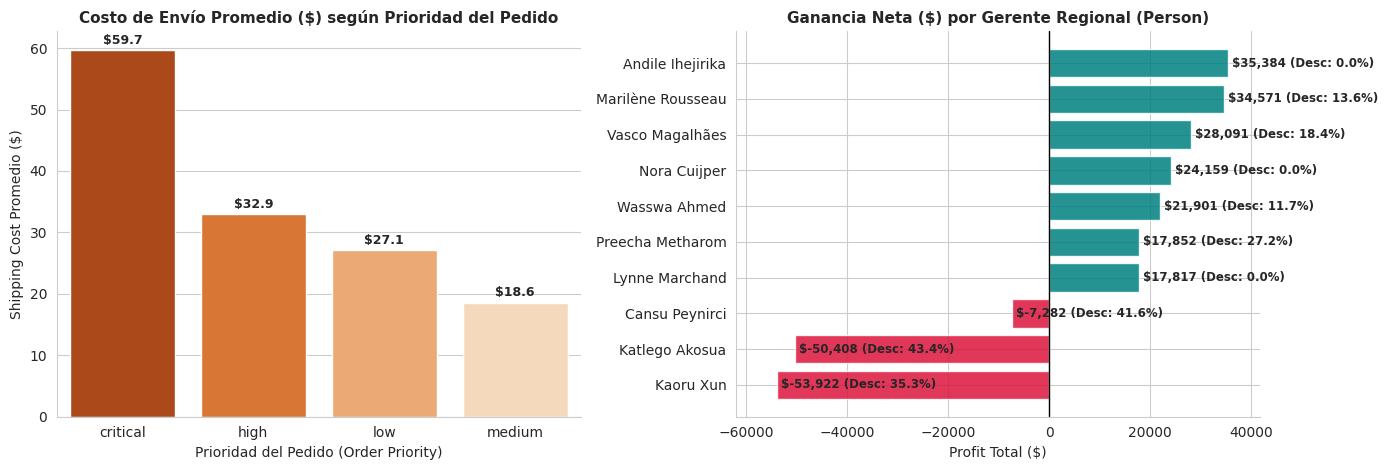

In [28]:
def auditar_gerentes_y_prioridad(df):
    """
    Evalúa el desempeño de los gerentes regionales (Person) y el impacto de Order Priority
    en los costos de envío y rentabilidad.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    # 1. Costo de Envío Promedio y Días de Envío según Order Priority
    orden_prio = ["low", "medium", "high", "critical"]
    prio_presentes = [p for p in orden_prio if p in df["Order Priority"].astype(str).str.lower().unique()]

    # Si están capitalizados en el dataset original, ajustamos dinámicamente
    resumen_prio = (df.groupby("Order Priority")
                      .agg(Pedidos=("Order ID", "count"),
                           Shipping_Cost_Medio=("Shipping Cost", "mean"),
                           Shipping_Days_Medio=("Shipping Days", "mean"),
                           Margen_Medio=("Margen", "mean"))
                      .sort_values(by="Shipping_Cost_Medio", ascending=False))

    sns.barplot(x=resumen_prio.index, y=resumen_prio["Shipping_Cost_Medio"],
                palette="Oranges_r", ax=axes[0])
    axes[0].set_title("Costo de Envío Promedio ($) según Prioridad del Pedido", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Prioridad del Pedido (Order Priority)")
    axes[0].set_ylabel("Shipping Cost Promedio ($)")

    for i, v in enumerate(resumen_prio["Shipping_Cost_Medio"]):
        axes[0].text(i, v + 1, f"${v:,.1f}", ha="center", fontsize=9, fontweight="bold")

    # 2. Rentabilidad y Descuento Promedio por Gerente Regional (Person) - Top 10 por Ventas
    if "Person" in df.columns:
        df_ger = df.copy()
        df_ger["Person"] = df_ger["Person"].str.title()
        gerentes = (df_ger.groupby("Person")
                          .agg(Pedidos=("Order ID", "count"),
                               Sales=("Sales", "sum"),
                               Profit=("Profit", "sum"),
                               Descuento_Medio=("Discount", "mean"),
                               Margen_Medio=("Margen", "mean"))
                          .sort_values(by="Profit", ascending=True)
                          .head(10))

        colores_ger = ["crimson" if p < 0 else "teal" for p in gerentes["Profit"]]
        axes[1].barh(gerentes.index, gerentes["Profit"], color=colores_ger, alpha=0.85)
        axes[1].axvline(0, color="black", linewidth=1)
        axes[1].set_title("Ganancia Neta ($) por Gerente Regional (Person)", fontsize=11, fontweight="bold")
        axes[1].set_xlabel("Profit Total ($)")
        axes[1].set_xlim(gerentes["Profit"].min() * 1.15 if gerentes["Profit"].min() < 0 else 0,
                         gerentes["Profit"].max() * 1.18)

        for i, (idx, row) in enumerate(gerentes.iterrows()):
            val = row["Profit"]
            desc = row["Descuento_Medio"] * 100
            axes[1].text(val, i, f" ${val:,.0f} (Desc: {desc:.1f}%)",
                         va="center", fontsize=8.5, fontweight="bold")

    sns.despine()
    plt.tight_layout()
    plt.show()

auditar_gerentes_y_prioridad(df)